# ElasticNet 80/20 Results Analysis

Place this notebook in the `new_pipeline_enet/` project root, next to `run_enet.sh`.

It scans `results_enet/*.h5`, summarizes internal 80/20 test metrics, checks completion, identifies well-predicted proteins by configurable thresholds, compares normalizations, and inspects saved model coefficients.

In [1]:
from pathlib import Path
import sys
import re
import json
import math
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import h5py
except ImportError as e:
    raise ImportError("This notebook requires h5py. Install with: conda install -c conda-forge h5py") from e

try:
    from joblib import load
except Exception:
    load = None

# Project layout: notebook is expected next to run_enet.sh
PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results_enet"
OUT_DIR = PROJECT_DIR / "analysis_enet"
OUT_DIR.mkdir(exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("PROJECT_DIR:", PROJECT_DIR)
print("SRC_DIR:", SRC_DIR)
print("DATA_DIR:", DATA_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("OUT_DIR:", OUT_DIR)
print("results_enet exists:", RESULTS_DIR.exists())

PROJECT_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet
SRC_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\src
DATA_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\data
RESULTS_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\results_enet
OUT_DIR: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\analysis_enet
results_enet exists: True


## Configure thresholds

Pearson and cosine are higher-is-better. MSE is lower-is-better and often scale-dependent, so the notebook uses both absolute cutoffs and percentile-based cutoffs.

In [2]:
# Good-prediction thresholds. Adjust these after seeing distributions.
PEARSON_GOOD = 0.30
PEARSON_STRONG = 0.50
COSINE_GOOD = 0.30
COSINE_STRONG = 0.50

# MSE cutoff options.
# If MSE_ABSOLUTE_CUTOFF is None, the notebook uses the 25th percentile of observed MSE as a data-driven cutoff.
MSE_ABSOLUTE_CUTOFF = None
MSE_PERCENTILE_FOR_GOOD = 25

# Expected output settings from your run. Used only for completion checks.
EXPECTED_NORMALIZATIONS = ["none", "zscore", "ranking", "binning"]
EXPECTED_GRID = "fast"
EXPECTED_SELECT_K = 500  # change if needed

print("Thresholds:")
print("  PEARSON_GOOD:", PEARSON_GOOD)
print("  PEARSON_STRONG:", PEARSON_STRONG)
print("  COSINE_GOOD:", COSINE_GOOD)
print("  COSINE_STRONG:", COSINE_STRONG)
print("  MSE_ABSOLUTE_CUTOFF:", MSE_ABSOLUTE_CUTOFF)
print("  MSE_PERCENTILE_FOR_GOOD:", MSE_PERCENTILE_FOR_GOOD)

Thresholds:
  PEARSON_GOOD: 0.3
  PEARSON_STRONG: 0.5
  COSINE_GOOD: 0.3
  COSINE_STRONG: 0.5
  MSE_ABSOLUTE_CUTOFF: None
  MSE_PERCENTILE_FOR_GOOD: 25


## Scan H5 outputs without loading all model artifacts

This reads only lightweight metrics/metadata from each H5 file. It does **not** unpickle the ElasticNet model for every file.

In [3]:
FILENAME_RE = re.compile(
    r"^(?P<protein>.+)_enet_8020_(?P<normalization>none|zscore|ranking|binning)_(?P<grid>tiny|fast|current)_k(?P<select_k>\d+)\.h5$"
)

def _json_from_h5(h5, key="metrics/json"):
    try:
        raw = bytes(h5[key][:]).decode("utf-8")
        return json.loads(raw)
    except Exception:
        return {}


def read_enet_h5_metadata(path: Path) -> dict:
    m = FILENAME_RE.match(path.name)
    from_name = m.groupdict() if m else {}
    row = {
        "file": path.name,
        "path": str(path),
        "size_bytes": path.stat().st_size,
        "protein": from_name.get("protein"),
        "normalization": from_name.get("normalization"),
        "grid": from_name.get("grid"),
        "select_k": int(from_name["select_k"]) if from_name.get("select_k") else np.nan,
    }
    try:
        with h5py.File(path, "r") as h5:
            metrics_json = _json_from_h5(h5)
            row["protein"] = str(metrics_json.get("protein", h5.attrs.get("protein", row["protein"])))
            mg = h5.get("metrics")
            if mg is not None:
                row["test_mse"] = float(mg.attrs.get("test_mse", metrics_json.get("test_mse", np.nan)))
                row["test_pearson_corr"] = float(mg.attrs.get("test_pearson_corr", metrics_json.get("test_pearson_corr", np.nan)))
                row["test_cosine_similarity"] = float(mg.attrs.get("test_cosine_similarity", metrics_json.get("test_cosine_similarity", np.nan)))
            else:
                row["test_mse"] = float(metrics_json.get("test_mse", np.nan))
                row["test_pearson_corr"] = float(metrics_json.get("test_pearson_corr", np.nan))
                row["test_cosine_similarity"] = float(metrics_json.get("test_cosine_similarity", np.nan))
            model_g = h5.get("model")
            if model_g is not None:
                row["selected_feature_count"] = int(model_g.attrs.get("selected_feature_count", len(metrics_json.get("selected_features", []))))
                row["coef_nonzero_count"] = int(model_g.attrs.get("coef_nonzero_count", -1))
            else:
                row["selected_feature_count"] = len(metrics_json.get("selected_features", []))
                row["coef_nonzero_count"] = np.nan
            row["n_train_samples"] = len(metrics_json.get("train_samples", []))
            row["n_test_samples"] = len(metrics_json.get("test_samples", []))
            row["best_params"] = metrics_json.get("best_params", {})
            row["read_ok"] = True
            row["error"] = ""
    except Exception as e:
        row.update({
            "test_mse": np.nan,
            "test_pearson_corr": np.nan,
            "test_cosine_similarity": np.nan,
            "selected_feature_count": np.nan,
            "coef_nonzero_count": np.nan,
            "n_train_samples": np.nan,
            "n_test_samples": np.nan,
            "best_params": {},
            "read_ok": False,
            "error": f"{type(e).__name__}: {e}",
        })
    return row

h5_files = sorted(RESULTS_DIR.glob("*.h5"))
print(f"Found {len(h5_files):,} H5 files in {RESULTS_DIR}")

rows = [read_enet_h5_metadata(p) for p in h5_files]
df = pd.DataFrame(rows)

if df.empty:
    print("No H5 files found. Check RESULTS_DIR or wait for jobs to finish.")
else:
    display(df.head())
    print("Columns:", list(df.columns))

Found 20,602 H5 files in c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\results_enet


,file,path,size_bytes,protein,normalization,grid,select_k,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,coef_nonzero_count,n_train_samples,n_test_samples,best_params,read_ok,error
0,A2M_enet_8020_binning10_fast_k2000.h5,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,102762,A2M,None,None,NaN,0.751558,0.511406,0.557465,2000,275,295,74,"{'_cv_mse': 1.2879188710408327, 'alpha': 0.1, ...",True,
1,A2M_enet_8020_binning10_fast_k500.h5,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,84639,A2M,None,None,NaN,0.828095,0.436132,0.511530,500,144,295,74,"{'_cv_mse': 1.2317880785491178, 'alpha': 0.1, ...",True,
2,A2M_enet_8020_none_fast_k2000.h5,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,102132,A2M,none,fast,2000.0,0.812740,0.427499,0.517441,2000,115,295,74,"{'_cv_mse': 1.245989258145567, 'alpha': 1.0, '...",True,
3,A2M_enet_8020_none_fast_k500.h5,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,84455,A2M,none,fast,500.0,0.783252,0.451198,0.538188,500,60,295,74,"{'_cv_mse': 1.1714027665052955, 'alpha': 1.0, ...",True,
4,A2M_enet_8020_ranking_fast_k2000.h5,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,103332,A2M,ranking,fast,2000.0,0.733483,0.492897,0.573536,2000,287,295,74,"{'_cv_mse': 1.1641936319442987, 'alpha': 0.1, ...",True,


Columns: ['file', 'path', 'size_bytes', 'protein', 'normalization', 'grid', 'select_k', 'test_mse', 'test_pearson_corr', 'test_cosine_similarity', 'selected_feature_count', 'coef_nonzero_count', 'n_train_samples', 'n_test_samples', 'best_params', 'read_ok', 'error']


## Basic completion and health checks

In [4]:
if not df.empty:
    print("Files read successfully:", int(df["read_ok"].sum()), "/", len(df))
    if (~df["read_ok"]).any():
        display(df.loc[~df["read_ok"], ["file", "error"]].head(20))

    print("Unique proteins in result files:", df["protein"].nunique())
    print("Normalizations found:", sorted(df["normalization"].dropna().unique().tolist()))
    print("Grids found:", sorted(df["grid"].dropna().unique().tolist()))
    print("select_k values found:", sorted(df["select_k"].dropna().astype(int).unique().tolist()))
    print("Total disk size:", f"{df['size_bytes'].sum() / 1024**3:.2f} GB")

    print("Counts by normalization:")
    display(df.groupby("normalization").size().rename("n_files").reset_index())

    print("Zero-coefficient models by normalization:")
    zero_summary = (
        df.assign(zero_coef=df["coef_nonzero_count"].fillna(-1).eq(0))
          .groupby("normalization")
          .agg(n_files=("file", "count"), zero_coef_models=("zero_coef", "sum"))
          .reset_index()
    )
    zero_summary["zero_coef_pct"] = 100 * zero_summary["zero_coef_models"] / zero_summary["n_files"]
    display(zero_summary)

    print("NaN metric counts by normalization:")    
    nan_summary = (
        df.groupby("normalization")[["test_mse", "test_pearson_corr", "test_cosine_similarity"]]
          .apply(lambda x: x.isna().sum())
          .reset_index()
    )
    display(nan_summary)

Files read successfully: 20602 / 20602
Unique proteins in result files: 5113
Normalizations found: ['none', 'ranking', 'zscore']
Grids found: ['fast']
select_k values found: [500, 2000]
Total disk size: 2.72 GB
Counts by normalization:


,normalization,n_files
0,none,5163
1,ranking,5113
2,zscore,5163


Zero-coefficient models by normalization:


,normalization,n_files,zero_coef_models,zero_coef_pct
0,none,5163,98,1.898121
1,ranking,5113,52,1.017015
2,zscore,5163,33,0.639163


NaN metric counts by normalization:


,normalization,test_mse,test_pearson_corr,test_cosine_similarity
0,none,0,93,0
1,ranking,0,52,0
2,zscore,0,29,0


## Optional expected-output check against `data/proteomics_matched.joblib`

This tries to infer the full protein list from the data file and shows missing outputs by normalization. It is safe if the data files are not present; the notebook will skip this section.

In [5]:
def detect_proteins_from_data(data_dir=DATA_DIR):
    if load is None:
        return None
    x_path = data_dir / "transcriptomics_filtered.joblib"
    y_path = data_dir / "proteomics_matched.joblib"
    if not x_path.exists() or not y_path.exists():
        return None
    X = load(x_path)
    Y = load(y_path)
    x_samples = pd.Index(map(str, X.index))
    y_index = pd.Index(map(str, Y.index))
    y_columns = pd.Index(map(str, Y.columns))
    index_overlap = len(x_samples.intersection(y_index))
    column_overlap = len(x_samples.intersection(y_columns))
    if index_overlap >= column_overlap:
        proteins = list(map(str, Y.columns))
        orientation = "samples_as_rows__proteins_as_columns"
    else:
        proteins = list(map(str, Y.index))
        orientation = "proteins_as_rows__samples_as_columns"
    return proteins, orientation, X.shape, Y.shape, index_overlap, column_overlap

if not df.empty:
    detected = detect_proteins_from_data()
    if detected is None:
        print("Data files not found or joblib unavailable; skipping expected-output check.")
    else:
        all_proteins, orientation, x_shape, y_shape, idx_overlap, col_overlap = detected
        print("Detected orientation:", orientation)
        print("Transcriptomics shape:", x_shape)
        print("Proteomics shape:", y_shape)
        print("Sample overlap Y.index:", idx_overlap)
        print("Sample overlap Y.columns:", col_overlap)
        print("Expected protein count:", len(all_proteins))
        expected_total = len(all_proteins) * len(EXPECTED_NORMALIZATIONS)
        print("Expected files for selected normalizations:", expected_total)
        print("Observed H5 files:", len(df))

        observed = set(zip(df["protein"], df["normalization"]))
        missing_rows = []
        for norm in EXPECTED_NORMALIZATIONS:
            for p in all_proteins:
                if (p, norm) not in observed:
                    missing_rows.append({"protein": p, "normalization": norm})
        missing_df = pd.DataFrame(missing_rows)
        print("Missing protein-normalization outputs:", len(missing_df))
        if not missing_df.empty:
            display(missing_df.groupby("normalization").size().rename("missing_count").reset_index())
            display(missing_df.head(20))
        else:
            print("No missing outputs for EXPECTED_NORMALIZATIONS.")

Detected orientation: samples_as_rows__proteins_as_columns
Transcriptomics shape: (369, 22614)
Proteomics shape: (369, 5113)
Sample overlap Y.index: 369
Sample overlap Y.columns: 0
Expected protein count: 5113
Expected files for selected normalizations: 20452
Observed H5 files: 20602
Missing protein-normalization outputs: 5113


,normalization,missing_count
0,binning,5113


,protein,normalization
0,A2M,binning
1,AAAS,binning
2,AACS,binning
3,AAGAB,binning
4,AAK1,binning
5,AAMDC,binning
6,AAMP,binning
7,AAR2,binning
8,AARS,binning
9,AARS2,binning


## Metric summaries by normalization

In [6]:
if not df.empty:
    metric_cols = ["test_mse", "test_pearson_corr", "test_cosine_similarity", "coef_nonzero_count", "selected_feature_count"]
    summary = (
        df.groupby("normalization")[metric_cols]
          .agg(["count", "mean", "median", "std", "min", "max"])
    )
    display(summary)

    compact_summary = df.groupby("normalization").agg(
        n_files=("file", "count"),
        n_proteins=("protein", "nunique"),
        pearson_median=("test_pearson_corr", "median"),
        pearson_mean=("test_pearson_corr", "mean"),
        cosine_median=("test_cosine_similarity", "median"),
        mse_median=("test_mse", "median"),
        mse_mean=("test_mse", "mean"),
        selected_features_median=("selected_feature_count", "median"),
        nonzero_coef_median=("coef_nonzero_count", "median"),
        file_size_mb_median=("size_bytes", lambda s: np.median(s) / 1024**2),
    ).reset_index()
    display(compact_summary)
    compact_summary.to_csv(OUT_DIR / "enet_summary_by_normalization.csv", index=False)
    print("Saved:", OUT_DIR / "enet_summary_by_normalization.csv")

test_mse                                                    \
                 count      mean    median       std       min       max   
normalization                                                              
none              5163  0.342021  0.289140  0.227567  0.054190  5.074216   
ranking           5113  0.381589  0.307918  0.278241  0.056663  5.299471   
zscore            5163  0.321010  0.260437  0.236447  0.052644  5.445015   

              test_pearson_corr                                ...  \
                          count      mean    median       std  ...   
normalization                                                  ...   
none                       5070  0.499025  0.494211  0.201882  ...   
ranking                    5061  0.460622  0.454650  0.185252  ...   
zscore                     5134  0.566285  0.576913  0.176446  ...   

              coef_nonzero_count                       selected_feature_count  \
                          median         std min   max                  count   
normalization                                                                   
none                        39.0   87.509863   0   863                   5163   
ranking                    143.0  165.989004   0  1017                   5113   
zscore                      33.0   53.291828   0   727                   5163   

                                                            
                      mean  median         std   min   max  
normalization                                               
none           1985.473562  2000.0  146.910926   500  2000  
ranking        2000.000000  2000.0    0.000000  2000  2000  
zscore         1985.473562  2000.0  146.910926   500  2000  

[3 rows x 30 columns]

,normalization,n_files,n_proteins,pearson_median,pearson_mean,cosine_median,mse_median,mse_mean,selected_features_median,nonzero_coef_median,file_size_mb_median
0,none,5163,5113,0.494211,0.499025,0.493181,0.289140,0.342021,2000.0,39.0,0.097056
1,ranking,5113,5113,0.454650,0.460622,0.456978,0.307918,0.381589,2000.0,143.0,0.097866
2,zscore,5163,5113,0.576913,0.566285,0.576414,0.260437,0.321010,2000.0,33.0,0.249046


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\analysis_enet\enet_summary_by_normalization.csv


## Define “well-predicted” proteins

The notebook reports several definitions:

- `good_pearson`: Pearson ≥ `PEARSON_GOOD`
- `strong_pearson`: Pearson ≥ `PEARSON_STRONG`
- `good_cosine`: cosine ≥ `COSINE_GOOD`
- `good_mse`: MSE ≤ cutoff, where cutoff is either absolute or a percentile of observed MSE
- `good_combined`: Pearson and cosine good, and MSE good

In [7]:
if not df.empty:
    mse_values = df["test_mse"].replace([np.inf, -np.inf], np.nan).dropna()
    if MSE_ABSOLUTE_CUTOFF is None:
        mse_cutoff = float(np.percentile(mse_values, MSE_PERCENTILE_FOR_GOOD)) if len(mse_values) else np.nan
        mse_cutoff_source = f"{MSE_PERCENTILE_FOR_GOOD}th percentile"
    else:
        mse_cutoff = float(MSE_ABSOLUTE_CUTOFF)
        mse_cutoff_source = "absolute cutoff"

    print("MSE good cutoff:", mse_cutoff, f"({mse_cutoff_source})")

    df2 = df.copy()
    df2["good_pearson"] = df2["test_pearson_corr"] >= PEARSON_GOOD
    df2["strong_pearson"] = df2["test_pearson_corr"] >= PEARSON_STRONG
    df2["good_cosine"] = df2["test_cosine_similarity"] >= COSINE_GOOD
    df2["strong_cosine"] = df2["test_cosine_similarity"] >= COSINE_STRONG
    df2["good_mse"] = df2["test_mse"] <= mse_cutoff
    df2["good_combined"] = df2["good_pearson"] & df2["good_cosine"] & df2["good_mse"]
    df2["zero_coef"] = df2["coef_nonzero_count"].fillna(-1).eq(0)

    threshold_summary = df2.groupby("normalization").agg(
        n_files=("file", "count"),
        good_pearson=("good_pearson", "sum"),
        strong_pearson=("strong_pearson", "sum"),
        good_cosine=("good_cosine", "sum"),
        strong_cosine=("strong_cosine", "sum"),
        good_mse=("good_mse", "sum"),
        good_combined=("good_combined", "sum"),
        zero_coef=("zero_coef", "sum"),
    ).reset_index()
    for c in ["good_pearson", "strong_pearson", "good_cosine", "strong_cosine", "good_mse", "good_combined", "zero_coef"]:
        threshold_summary[c + "_pct"] = 100 * threshold_summary[c] / threshold_summary["n_files"]

    display(threshold_summary)
    threshold_summary.to_csv(OUT_DIR / "enet_threshold_summary.csv", index=False)
    print("Saved:", OUT_DIR / "enet_threshold_summary.csv")
else:
    df2 = df.copy()

MSE good cutoff: 0.21454549280696855 (25th percentile)


,normalization,n_files,good_pearson,strong_pearson,good_cosine,strong_cosine,good_mse,good_combined,zero_coef,good_pearson_pct,strong_pearson_pct,good_cosine_pct,strong_cosine_pct,good_mse_pct,good_combined_pct,zero_coef_pct
0,none,5163,4172,2491,4281,2520,1295,869,98,80.805733,48.247143,82.916909,48.808832,25.082316,16.831300,1.898121
1,ranking,5113,4034,2077,4128,2092,1203,790,52,78.896929,40.621944,80.735380,40.915314,23.528261,15.450812,1.017015
2,zscore,5163,4753,3349,4802,3412,1711,1465,33,92.058880,64.865388,93.007941,66.085609,33.139647,28.374976,0.639163


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\analysis_enet\enet_threshold_summary.csv


## Plots: distributions and normalization comparison

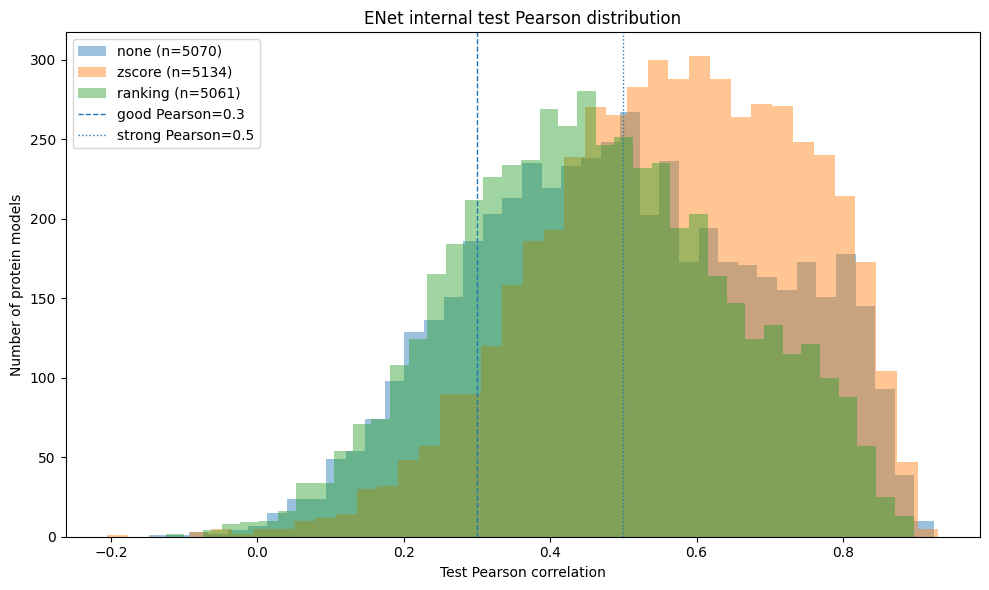

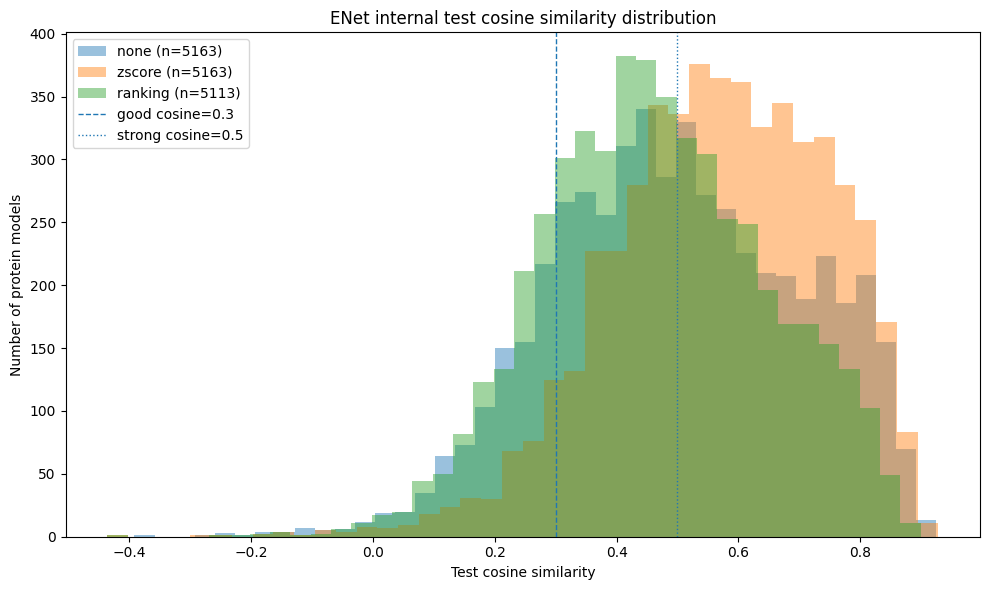

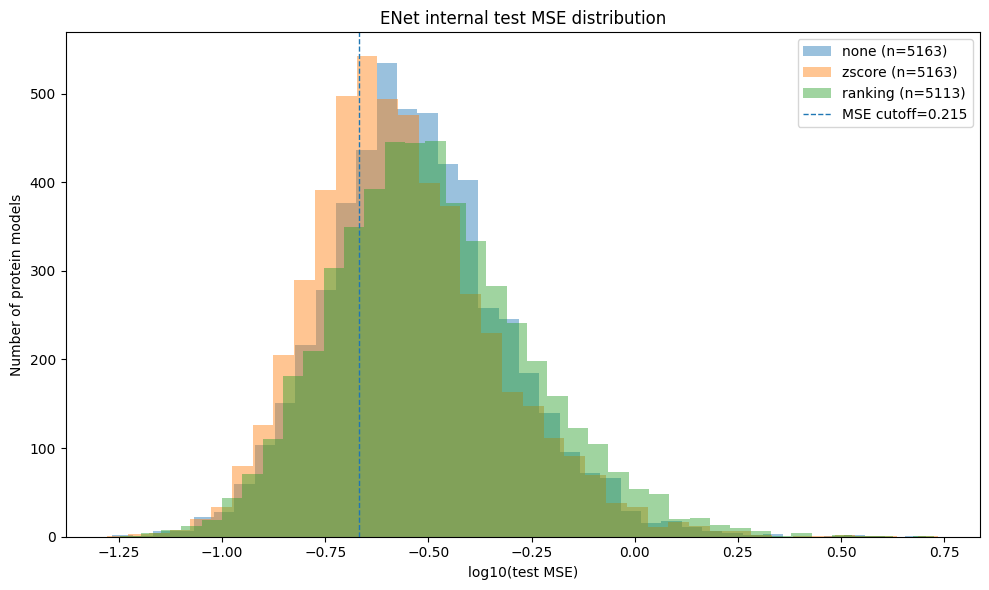

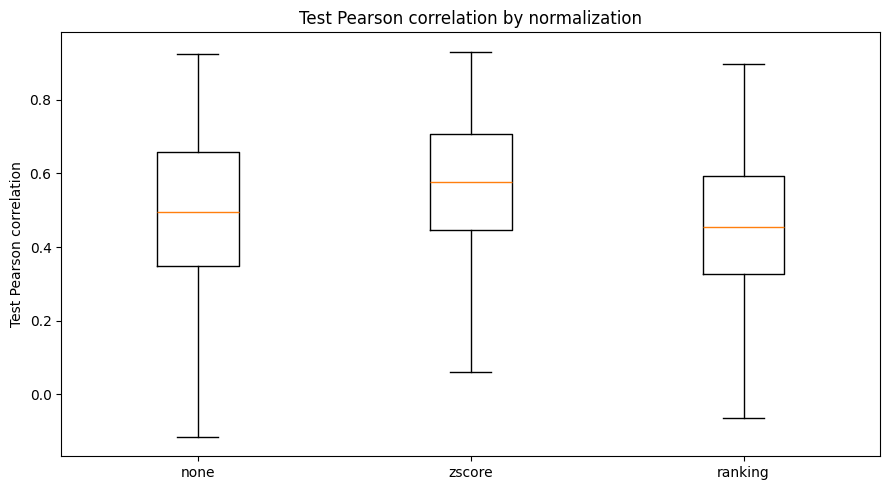

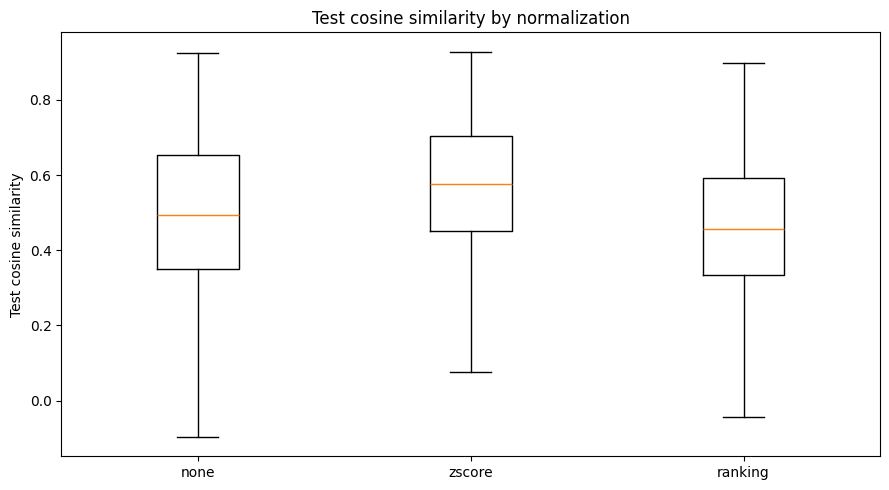

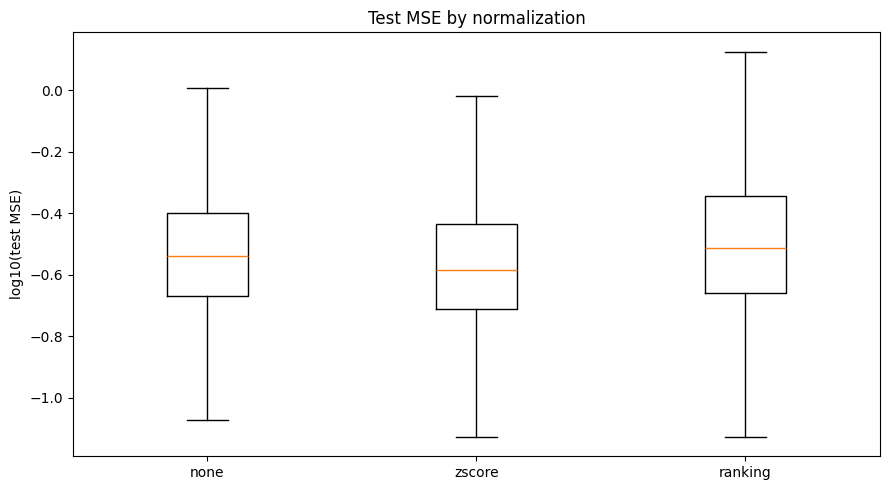

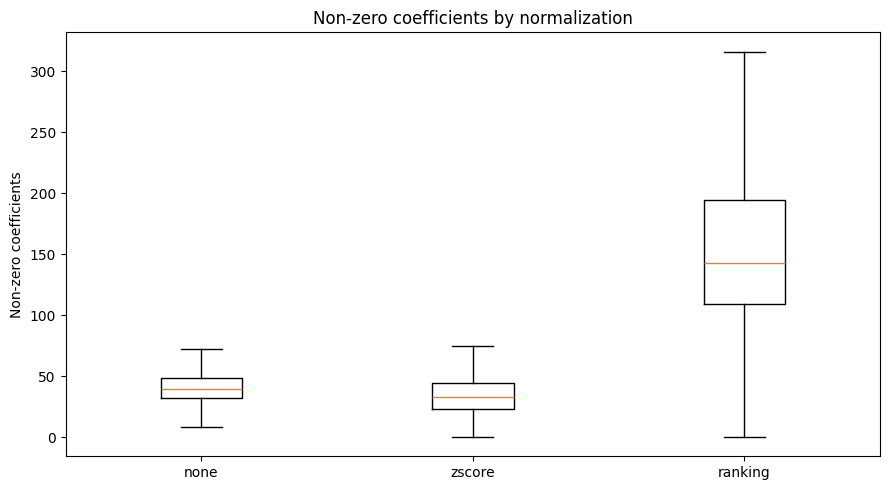

In [8]:
def _norm_order(data):
    preferred = ["none", "zscore", "ranking", "binning"]
    existing = list(data["normalization"].dropna().unique())
    return [x for x in preferred if x in existing] + [x for x in existing if x not in preferred]

if not df.empty:
    norms = _norm_order(df)

    # Pearson histogram by normalization
    plt.figure(figsize=(10, 6))
    for norm in norms:
        vals = df.loc[df["normalization"] == norm, "test_pearson_corr"].dropna()
        if len(vals):
            plt.hist(vals, bins=40, alpha=0.45, label=f"{norm} (n={len(vals)})")
    plt.axvline(PEARSON_GOOD, linestyle="--", linewidth=1, label=f"good Pearson={PEARSON_GOOD}")
    plt.axvline(PEARSON_STRONG, linestyle=":", linewidth=1, label=f"strong Pearson={PEARSON_STRONG}")
    plt.xlabel("Test Pearson correlation")
    plt.ylabel("Number of protein models")
    plt.title("ENet internal test Pearson distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Cosine histogram by normalization
    plt.figure(figsize=(10, 6))
    for norm in norms:
        vals = df.loc[df["normalization"] == norm, "test_cosine_similarity"].dropna()
        if len(vals):
            plt.hist(vals, bins=40, alpha=0.45, label=f"{norm} (n={len(vals)})")
    plt.axvline(COSINE_GOOD, linestyle="--", linewidth=1, label=f"good cosine={COSINE_GOOD}")
    plt.axvline(COSINE_STRONG, linestyle=":", linewidth=1, label=f"strong cosine={COSINE_STRONG}")
    plt.xlabel("Test cosine similarity")
    plt.ylabel("Number of protein models")
    plt.title("ENet internal test cosine similarity distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # MSE log histogram
    plt.figure(figsize=(10, 6))
    for norm in norms:
        vals = df.loc[df["normalization"] == norm, "test_mse"].replace([np.inf, -np.inf], np.nan).dropna()
        vals = vals[vals > 0]
        if len(vals):
            plt.hist(np.log10(vals), bins=40, alpha=0.45, label=f"{norm} (n={len(vals)})")
    if 'mse_cutoff' in globals() and np.isfinite(mse_cutoff) and mse_cutoff > 0:
        plt.axvline(np.log10(mse_cutoff), linestyle="--", linewidth=1, label=f"MSE cutoff={mse_cutoff:.3g}")
    plt.xlabel("log10(test MSE)")
    plt.ylabel("Number of protein models")
    plt.title("ENet internal test MSE distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Boxplots
    for metric, label in [
        ("test_pearson_corr", "Test Pearson correlation"),
        ("test_cosine_similarity", "Test cosine similarity"),
        ("test_mse", "Test MSE"),
        ("coef_nonzero_count", "Non-zero coefficients"),
    ]:
        data = []
        labels = []
        for norm in norms:
            vals = df.loc[df["normalization"] == norm, metric].replace([np.inf, -np.inf], np.nan).dropna()
            if metric == "test_mse":
                vals = vals[vals > 0]
                vals = np.log10(vals)
                ylabel = "log10(test MSE)"
            else:
                ylabel = label
            if len(vals):
                data.append(vals)
                labels.append(norm)
        if data:
            plt.figure(figsize=(9, 5))
            plt.boxplot(data, tick_labels=labels, showfliers=False)
            plt.ylabel(ylabel)
            plt.title(f"{label} by normalization")
            plt.tight_layout()
            plt.show()

## Plots: how many proteins pass thresholds?

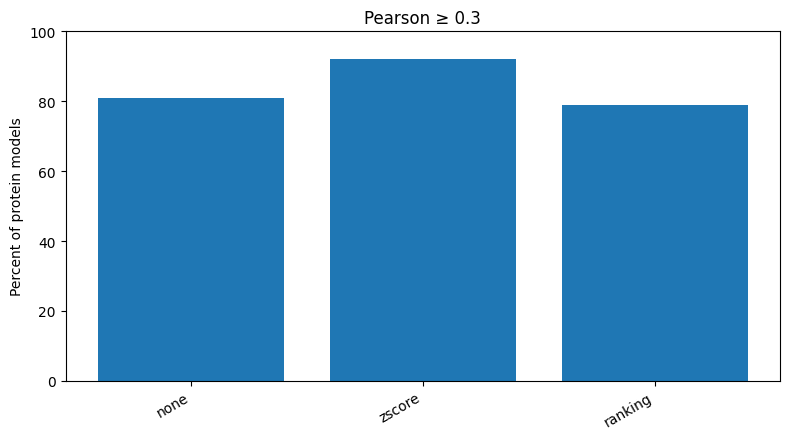

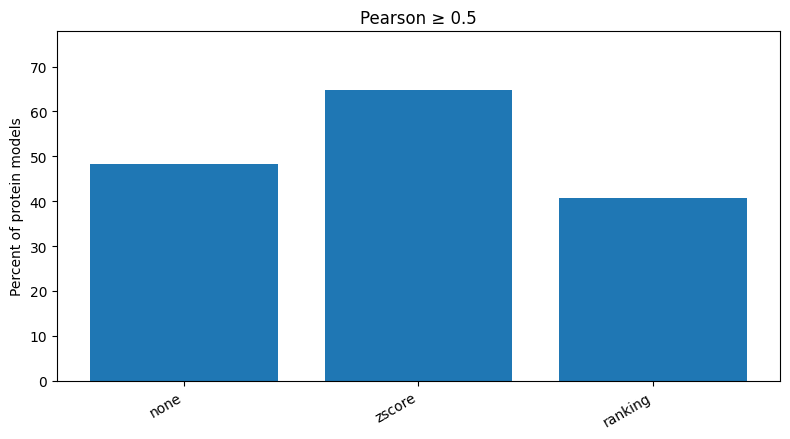

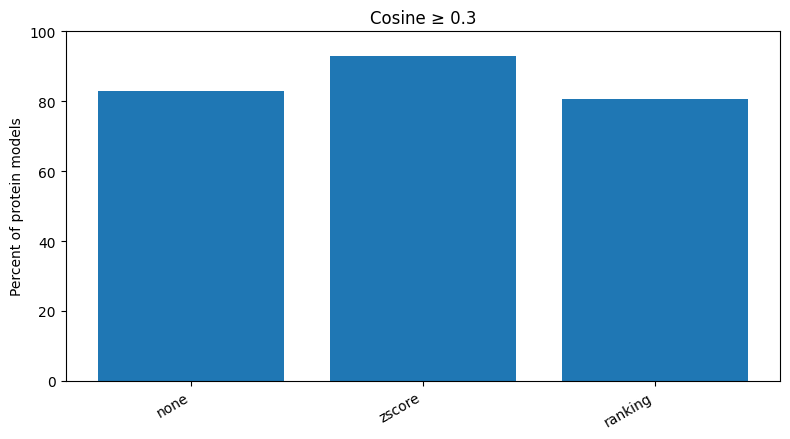

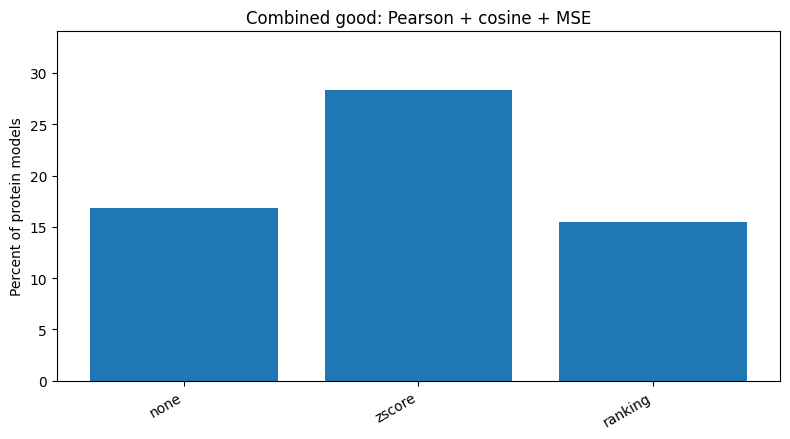

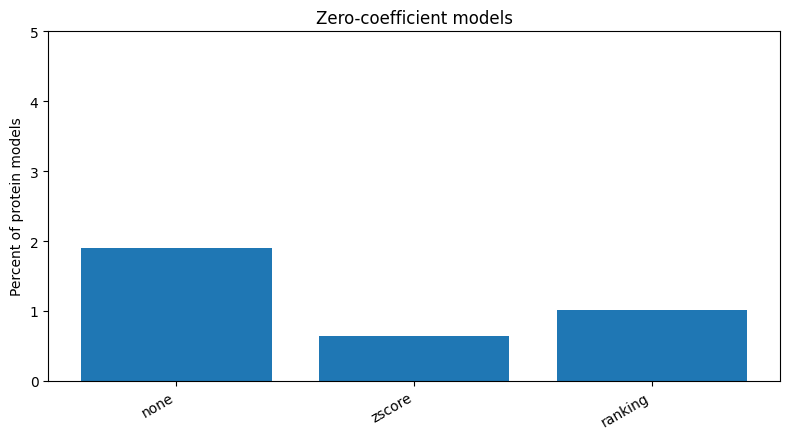

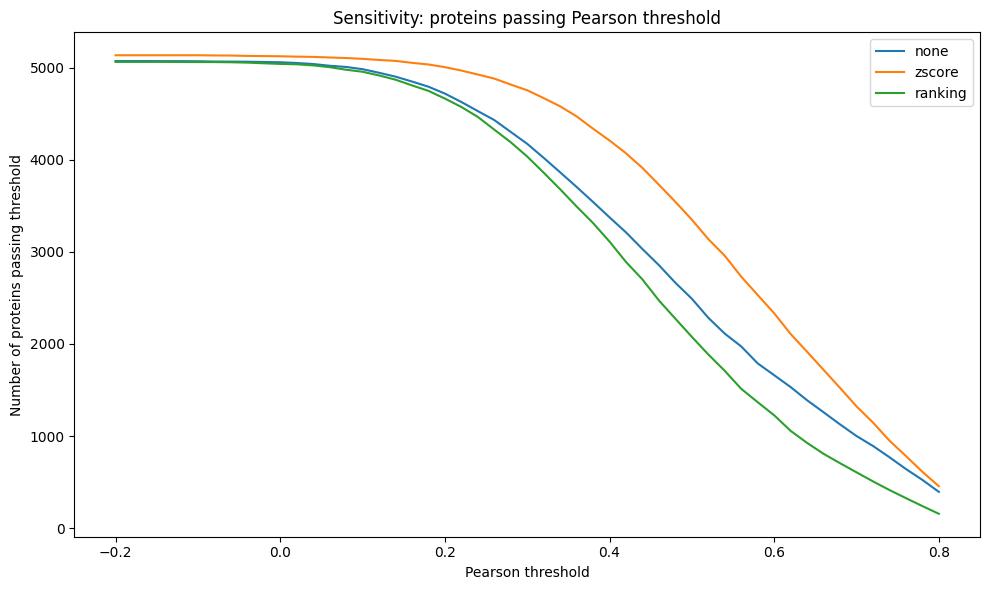

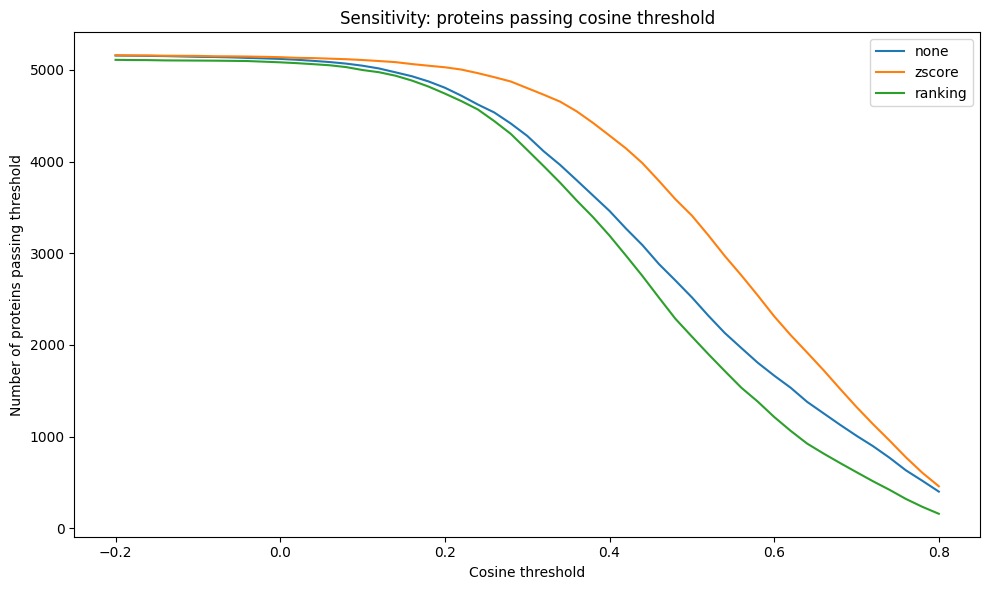

In [9]:
if not df.empty:
    # Bar charts for threshold percentages
    if 'threshold_summary' in globals():
        for col, title in [
            ("good_pearson_pct", f"Pearson ≥ {PEARSON_GOOD}"),
            ("strong_pearson_pct", f"Pearson ≥ {PEARSON_STRONG}"),
            ("good_cosine_pct", f"Cosine ≥ {COSINE_GOOD}"),
            ("good_combined_pct", "Combined good: Pearson + cosine + MSE"),
            ("zero_coef_pct", "Zero-coefficient models"),
        ]:
            plot_df = threshold_summary.set_index("normalization").reindex(norms).reset_index()
            plt.figure(figsize=(8, 4.5))
            plt.bar(plot_df["normalization"], plot_df[col])
            plt.ylabel("Percent of protein models")
            plt.ylim(0, max(5, min(100, np.nanmax(plot_df[col]) * 1.2 if len(plot_df) else 100)))
            plt.title(title)
            plt.xticks(rotation=30, ha="right")
            plt.tight_layout()
            plt.show()

    # Threshold sensitivity curves
    pearson_thresholds = np.linspace(-0.2, 0.8, 51)
    plt.figure(figsize=(10, 6))
    for norm in norms:
        vals = df.loc[df["normalization"] == norm, "test_pearson_corr"].dropna()
        if len(vals):
            counts = [(vals >= t).sum() for t in pearson_thresholds]
            plt.plot(pearson_thresholds, counts, label=norm)
    plt.xlabel("Pearson threshold")
    plt.ylabel("Number of proteins passing threshold")
    plt.title("Sensitivity: proteins passing Pearson threshold")
    plt.legend()
    plt.tight_layout()
    plt.show()

    cosine_thresholds = np.linspace(-0.2, 0.8, 51)
    plt.figure(figsize=(10, 6))
    for norm in norms:
        vals = df.loc[df["normalization"] == norm, "test_cosine_similarity"].dropna()
        if len(vals):
            counts = [(vals >= t).sum() for t in cosine_thresholds]
            plt.plot(cosine_thresholds, counts, label=norm)
    plt.xlabel("Cosine threshold")
    plt.ylabel("Number of proteins passing threshold")
    plt.title("Sensitivity: proteins passing cosine threshold")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Best normalization per protein

This ranks each protein’s normalization-specific models by:

1. higher Pearson,
2. higher cosine,
3. lower MSE.

Best-normalization rows: 5113


,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,coef_nonzero_count,selected_feature_count,path
0,A2M,None,0.511406,0.557465,0.751558,275,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1,AAAS,zscore,0.637295,0.646450,0.102694,220,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2,AACS,zscore,0.675858,0.668078,0.357902,42,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3,AAGAB,none,0.475606,0.465451,0.450723,24,500,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4,AAK1,zscore,0.730509,0.735883,0.261418,29,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
5,AAMDC,zscore,0.545740,0.523851,0.644101,59,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
6,AAMP,zscore,0.383026,0.390920,0.446038,38,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
7,AAR2,zscore,0.480588,0.532701,0.129474,15,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
8,AARS,ranking,0.546756,0.515504,0.360432,702,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
9,AARS2,zscore,0.420565,0.440778,0.215023,20,500,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


Best normalization counts:


,normalization,n_best,pct_best
0,zscore,3865,75.591629
1,none,767,15.000978
2,ranking,374,7.314688


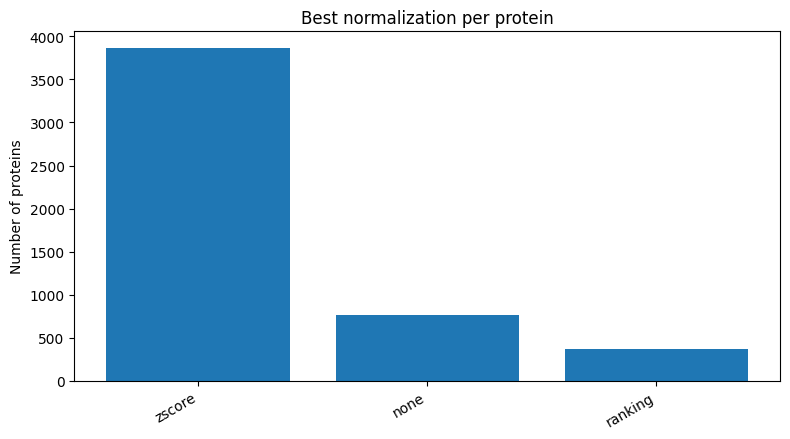

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\analysis_enet\enet_best_normalization_per_protein.csv


In [11]:
if not df.empty:
    rank_df = df.copy()
    rank_df["pearson_rank_value"] = rank_df["test_pearson_corr"].fillna(-np.inf)
    rank_df["cosine_rank_value"] = rank_df["test_cosine_similarity"].fillna(-np.inf)
    rank_df["mse_rank_value"] = rank_df["test_mse"].replace([np.inf, -np.inf], np.nan).fillna(np.inf)

    best_per_protein = (
        rank_df.sort_values(
            ["protein", "pearson_rank_value", "cosine_rank_value", "mse_rank_value"],
            ascending=[True, False, False, True],
        )
        .groupby("protein", as_index=False)
        .head(1)
        .drop(columns=["pearson_rank_value", "cosine_rank_value", "mse_rank_value"])
        .reset_index(drop=True)
    )

    print("Best-normalization rows:", len(best_per_protein))
    display(best_per_protein[[
        "protein", "normalization", "test_pearson_corr", "test_cosine_similarity", "test_mse",
        "coef_nonzero_count", "selected_feature_count", "path"
    ]].head(20))

    print("Best normalization counts:")
    best_counts = best_per_protein["normalization"].value_counts().rename_axis("normalization").reset_index(name="n_best")
    best_counts["pct_best"] = 100 * best_counts["n_best"] / len(best_per_protein)
    display(best_counts)

    plt.figure(figsize=(8, 4.5))
    plt.bar(best_counts["normalization"], best_counts["n_best"])
    plt.ylabel("Number of proteins")
    plt.title("Best normalization per protein")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    best_per_protein.to_csv(OUT_DIR / "enet_best_normalization_per_protein.csv", index=False)
    print("Saved:", OUT_DIR / "enet_best_normalization_per_protein.csv")

## Top and bottom proteins by internal test performance

In [13]:
if not df.empty:
    display_cols = [
        "protein", "normalization", "test_pearson_corr", "test_cosine_similarity", "test_mse",
        "coef_nonzero_count", "selected_feature_count", "path"
    ]
    print("Top 30 models by Pearson:")
    top_pearson = df.sort_values("test_pearson_corr", ascending=False)[display_cols].head(30)
    display(top_pearson)

    print("Top 30 best-per-protein by Pearson:")
    if 'best_per_protein' in globals():
        display(best_per_protein.sort_values("test_pearson_corr", ascending=False)[display_cols].head(30))

    print("Lowest 30 models by MSE:")
    display(df.sort_values("test_mse", ascending=True)[display_cols].head(30))

    print("Worst 30 models by Pearson:")
    display(df.sort_values("test_pearson_corr", ascending=True)[display_cols].head(30))

    df.to_csv(OUT_DIR / "enet_all_h5_metrics.csv", index=False)
    print("Saved:", OUT_DIR / "enet_all_h5_metrics.csv")

Top 30 models by Pearson:


,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,coef_nonzero_count,selected_feature_count,path
2469,CAMK2D,zscore,0.930501,0.926134,0.203711,19,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
8217,IGF2BP1,zscore,0.927995,0.928496,0.373599,23,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
8215,IGF2BP1,none,0.924400,0.924930,0.378763,35,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
809,ALDH1A1,zscore,0.921062,0.919425,0.613598,54,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
807,ALDH1A1,none,0.914918,0.913496,0.602763,58,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
9602,MAP1B,None,0.914305,0.914568,0.560723,11,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
9605,MAP1B,zscore,0.910822,0.912164,0.381529,32,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
8214,IGF2BP1,None,0.908862,0.903095,0.774461,3,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2466,CAMK2D,None,0.907163,0.792006,0.884589,1,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
12543,PDLIM1,none,0.905143,0.906004,0.289708,44,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


Top 30 best-per-protein by Pearson:


,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,coef_nonzero_count,selected_feature_count,path
579,CAMK2D,zscore,0.930501,0.926134,0.203711,19,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2016,IGF2BP1,zscore,0.927995,0.928496,0.373599,23,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
164,ALDH1A1,zscore,0.921062,0.919425,0.613598,54,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2363,MAP1B,None,0.914305,0.914568,0.560723,11,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3098,PDLIM1,none,0.905143,0.906004,0.289708,44,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2346,MAGEA4,none,0.904128,0.914210,0.535571,1,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2069,IQGAP2,None,0.904031,0.883805,0.687905,8,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2458,MET,zscore,0.903814,0.900498,0.391333,38,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1506,FAM84B,zscore,0.901182,0.894199,0.511313,30,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3497,PTK7,none,0.901052,0.900886,0.317902,42,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


Lowest 30 models by MSE:


,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,coef_nonzero_count,selected_feature_count,path
13977,PSMC1,zscore,0.526950,0.541768,0.052644,158,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13975,PSMC1,none,0.451788,0.452067,0.054190,18,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13987,PSMC4,none,0.371835,0.376554,0.056067,16,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13976,PSMC1,ranking,0.418456,0.424075,0.056663,56,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13974,PSMC1,None,0.382047,0.384634,0.057819,83,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13978,PSMC2,None,0.313807,0.302128,0.058886,83,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13991,PSMC5,none,0.277458,0.276688,0.060707,18,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13990,PSMC5,None,0.303207,0.285411,0.060942,104,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
15361,RPLP0,zscore,-0.040554,0.029221,0.060964,4,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13986,PSMC4,None,0.237657,0.250979,0.061892,101,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


Worst 30 models by Pearson:


,protein,normalization,test_pearson_corr,test_cosine_similarity,test_mse,coef_nonzero_count,selected_feature_count,path
18258,TK1,None,-0.224291,0.177755,0.909096,0,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
9502,LZTFL1,None,-0.213739,-0.075812,0.622605,0,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
13925,PSMA5,zscore,-0.205056,-0.276613,0.121247,0,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3786,COPG2,None,-0.179576,-0.054082,0.395556,236,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
12842,PHKA2,None,-0.161680,-0.161314,0.388322,293,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
10430,MRPL42,None,-0.154191,-0.095893,0.474408,140,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2239,C14orf166,none,-0.147341,-0.162464,0.110861,20,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
11266,NEDD1,None,-0.129807,-0.116323,0.259406,190,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1998,BIRC2,None,-0.129382,-0.115412,0.415840,217,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2240,C14orf166,ranking,-0.125352,-0.157046,0.110982,53,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\analysis_enet\enet_all_h5_metrics.csv


## Relationship between sparsity and performance

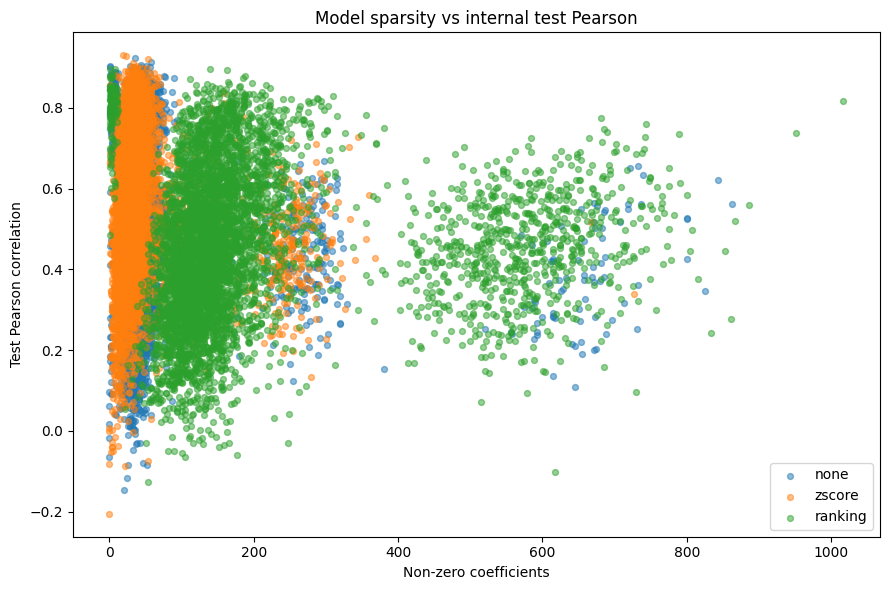

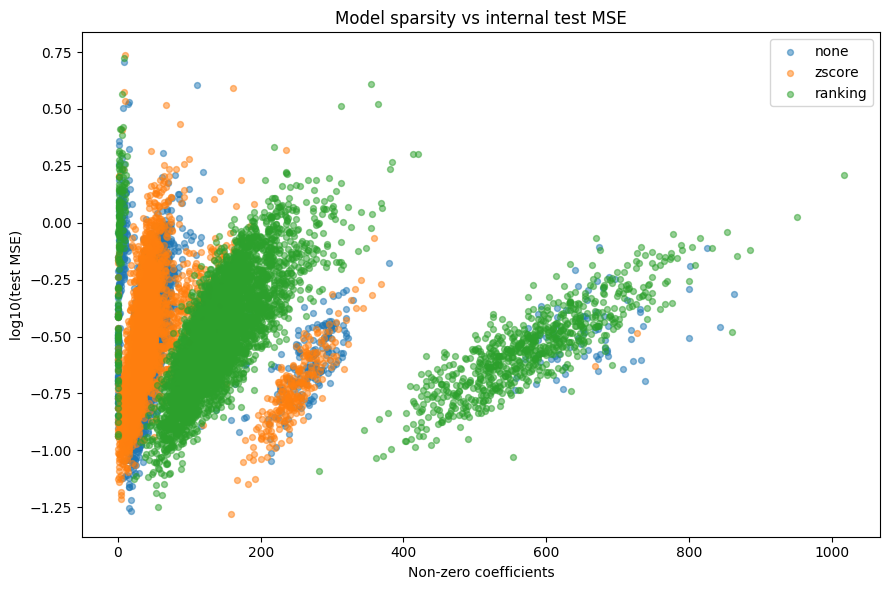

In [14]:
if not df.empty:
    plot_df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["coef_nonzero_count", "test_pearson_corr"])
    if len(plot_df):
        plt.figure(figsize=(9, 6))
        for norm in norms:
            sub = plot_df[plot_df["normalization"] == norm]
            if len(sub):
                plt.scatter(sub["coef_nonzero_count"], sub["test_pearson_corr"], alpha=0.5, s=18, label=norm)
        plt.xlabel("Non-zero coefficients")
        plt.ylabel("Test Pearson correlation")
        plt.title("Model sparsity vs internal test Pearson")
        plt.legend()
        plt.tight_layout()
        plt.show()

    plot_df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["coef_nonzero_count", "test_mse"])
    plot_df = plot_df[plot_df["test_mse"] > 0]
    if len(plot_df):
        plt.figure(figsize=(9, 6))
        for norm in norms:
            sub = plot_df[plot_df["normalization"] == norm]
            if len(sub):
                plt.scatter(sub["coef_nonzero_count"], np.log10(sub["test_mse"]), alpha=0.5, s=18, label=norm)
        plt.xlabel("Non-zero coefficients")
        plt.ylabel("log10(test MSE)")
        plt.title("Model sparsity vs internal test MSE")
        plt.legend()
        plt.tight_layout()
        plt.show()

## Inspect a saved model and feature weights

This loads one model artifact, so it is intentionally done for one file only. By default it inspects the best model by Pearson.

In [15]:
# Set manually to inspect a specific file, or leave as None to use best Pearson model.
INSPECT_H5 = None

if not df.empty:
    if INSPECT_H5 is None:
        inspect_row = df.sort_values("test_pearson_corr", ascending=False).iloc[0]
        inspect_path = Path(inspect_row["path"])
    else:
        inspect_path = Path(INSPECT_H5)
    print("Inspecting:", inspect_path)

    try:
        from functions import load_enet_8020_h5, predict_with_artifact
        loaded = load_enet_8020_h5(str(inspect_path))
        artifact = loaded["model_artifact"]
        model = artifact["model"]
        features = list(map(str, artifact.get("selected_features", [])))
        coefs = np.asarray(getattr(model, "coef_", []), dtype=float)
        weights = pd.DataFrame({"gene": features[:len(coefs)], "coef": coefs[:len(features)]})
        weights["abs_coef"] = weights["coef"].abs()
        weights_nonzero = weights[weights["coef"] != 0].sort_values("abs_coef", ascending=False)

        print("Protein:", artifact.get("protein"))
        print("Normalization:", artifact.get("normalization"))
        print("Params:", artifact.get("params"))
        print("Selected features:", len(features))
        print("Non-zero coefficients:", len(weights_nonzero))
        print("Intercept:", artifact.get("intercept"))
        print("Training samples for final model:", artifact.get("n_training_samples_final_model"))

        display(weights_nonzero.head(30))

        if len(weights_nonzero):
            topw = weights_nonzero.head(25).iloc[::-1]
            plt.figure(figsize=(9, max(5, len(topw) * 0.25)))
            plt.barh(topw["gene"], topw["coef"])
            plt.xlabel("ElasticNet coefficient")
            plt.title(f"Top coefficients: {artifact.get('protein')} ({artifact.get('normalization')})")
            plt.tight_layout()
            plt.show()
        else:
            print("This inspected model has all coefficients equal to zero.")
    except Exception as e:
        print("Could not load artifact. Error:", type(e).__name__, e)

Inspecting: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\new_pipeline_enet\results_enet\CAMK2D_enet_8020_zscore_fast_k2000.h5
Could not load artifact. Error: ModuleNotFoundError No module named 'numpy._core.numeric'


## Optional: predict with one saved model on a validation transcriptomics matrix

Set `VALIDATION_X_PATH` to a joblib file with rows as samples and columns as genes. This uses the saved model and its selected features/normalizer.

In [16]:
VALIDATION_X_PATH = None  # example: Path("data/validation_transcriptomics_filtered.joblib")
MODEL_FOR_PREDICTION = None  # None = best Pearson model, or set to an H5 path

if VALIDATION_X_PATH is not None:
    if load is None:
        raise RuntimeError("joblib is not available")
    from functions import load_enet_8020_h5, predict_with_artifact
    model_path = Path(MODEL_FOR_PREDICTION) if MODEL_FOR_PREDICTION is not None else Path(df.sort_values("test_pearson_corr", ascending=False).iloc[0]["path"])
    X_val = load(VALIDATION_X_PATH)
    loaded = load_enet_8020_h5(str(model_path))
    pred = predict_with_artifact(loaded["model_artifact"], X_val)
    display(pred.head())
    pred.to_csv(OUT_DIR / f"predictions_{model_path.stem}.csv", header=True)
    print("Saved:", OUT_DIR / f"predictions_{model_path.stem}.csv")
else:
    print("Set VALIDATION_X_PATH to run external prediction from a saved ENet H5 model.")

Set VALIDATION_X_PATH to run external prediction from a saved ENet H5 model.


## Quick interpretation guide

- `test_pearson_corr`: linear agreement on the internal 20% test split; higher is better. NaN usually means predictions or targets have zero variance.
- `test_cosine_similarity`: directional similarity between true and predicted vectors; higher is better. NaN can occur for all-zero prediction vectors.
- `test_mse`: squared error on the internal 20% test split; lower is better.
- `coef_nonzero_count`: number of selected features with non-zero ElasticNet weights. Many zero-coefficient models usually means the alpha/l1 penalty is too strong, the feature subset is too small, or the protein is hard to predict.

Use the best-normalization table as a screening tool, then validate selected models on the external dataset.